# Study 3 Analyses

Code to generate figures for Study 3.

In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
import os
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
sns.set_style("ticks")

import helpers
import regression_utils
import qualitative_utils
import generalization_utils

## Generate Quantitative Featurizer Comparison

  'Matry.\n+ surprisal' vs 'Matry.': p_raw=0.0021, p_adj=0.0085  **
  'Matry.\n+ surprisal' vs 'Benara\n2024': p_raw=0.0016, p_adj=0.0065  **
  'Matry.\n+ surprisal' vs 'Eng1000': p_raw=0.0000, p_adj=0.0001  ***
  'Matry.\n+ surprisal' vs 'Zeng &\nGallant 2025': p_raw=0.0000, p_adj=0.0001  ***


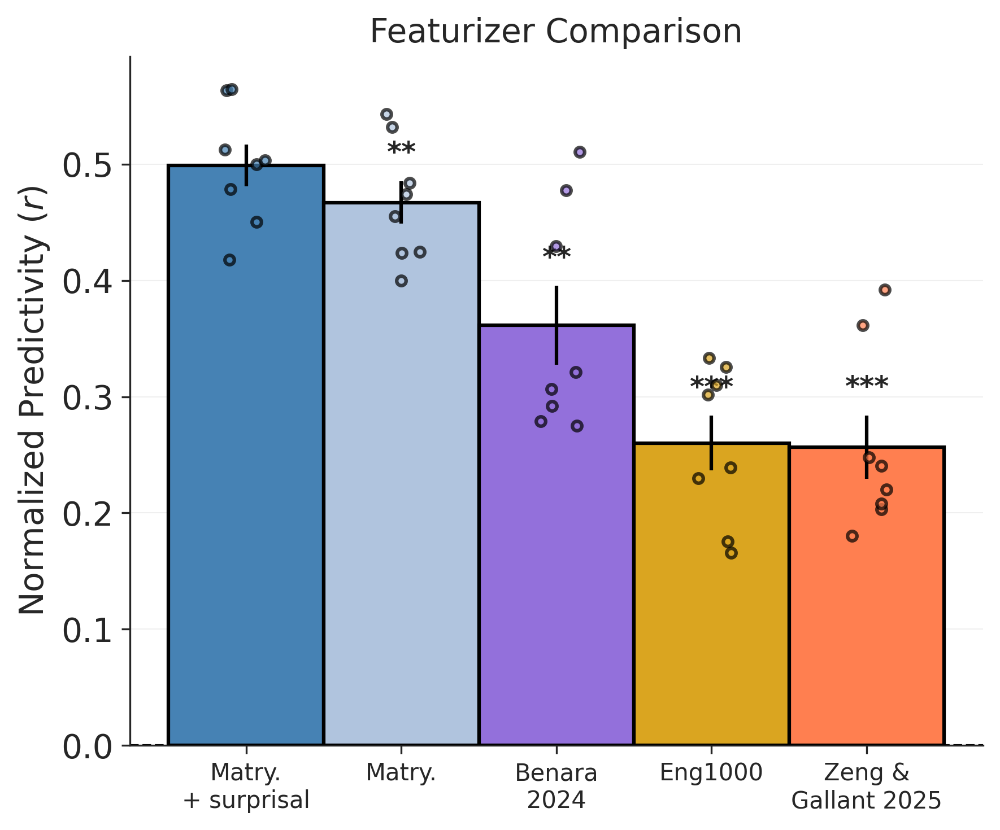

In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RESULTS_BASE = os.path.join("..", "results_anon", "fROI")
DATA_BASE = os.path.join("..", "data", "processed_csvs_anon")
META_BASENAME = "langfroi12345"
YCOL = "NC Normalized R Fischer"

FEATURIZER_PATHS = {
    "Matry.\n+ surprisal": {
        "base": os.path.join(RESULTS_BASE, "full_features", "regressions", "sae",
                             "gemma-2-2b-res-matryoshka-dc", "mean", "12",
                             "standardized_betas", "regressions"),
        "results_file": "results_langfroi12345_20260311.csv",
    },
    "Matry.": {
        "base": os.path.join(RESULTS_BASE, "content_only", "regressions", "sae",
                             "gemma-2-2b-res-matryoshka-dc", "mean", "12",
                             "standardized_betas", "regressions"),
        "results_file": "results.csv",
    },
    "Benara\n2024": {
        "base": os.path.join(RESULTS_BASE, "content_only", "regressions", "benara2024",
                             "mean", "12", "standardized_features_and_betas", "regressions"),
        "results_file": "results.csv",
    },
    "Eng1000": {
        "base": os.path.join(RESULTS_BASE, "content_only", "regressions", "eng1000",
                             "mean", "12", "standardized_betas", "regressions"),
        "results_file": "results.csv",
    },
    "Zeng &\nGallant 2025": {
        "base": os.path.join(RESULTS_BASE, "content_only", "regressions", "zeng_gallant2025",
                             "mean", "12", "standardized_betas", "regressions"),
        "results_file": "results.csv",
    },
}
FEATURIZER_ORDER = list(FEATURIZER_PATHS.keys())


def _load_and_dedup(base, results_file, participant_id):
    df = pd.read_csv(os.path.join(base, participant_id, results_file))
    meta = pd.read_csv(os.path.join(DATA_BASE, participant_id, f"{META_BASENAME}_meta.csv"))
    df = df.merge(meta[["neuroid_id", "top10_tstat_langloc_SN_parc_lang_int"]],
                  left_on="neuroid", right_on="neuroid_id", how="left")
    betas = pd.read_csv(os.path.join(DATA_BASE, participant_id, f"{META_BASENAME}_betas.csv"),
                        index_col=0)
    seen, unique_nids = {}, set()
    for col in betas.columns:
        key = tuple(betas[col].values)
        if key not in seen:
            seen[key] = col
            unique_nids.add(int(col))
    return df[df["neuroid"].isin(unique_nids)]


# --- Load per-participant means ---
records = []
for feat_name, pinfo in FEATURIZER_PATHS.items():
    for pid in helpers.PARTICIPANTS:
        df_p = _load_and_dedup(pinfo["base"], pinfo["results_file"], pid)
        records.append({"Featurizer": feat_name, "Participant": pid,
                        YCOL: df_p[YCOL].mean()})
df_comp = pd.DataFrame(records)

# --- Significance: paired t-tests vs Matryoshka+surprisal, Bonferroni-corrected ---
ref = "Matry.\n+ surprisal"
comparisons = [f for f in FEATURIZER_ORDER if f != ref]
p_raw = []
for feat in comparisons:
    ref_vals = df_comp[df_comp["Featurizer"] == ref].sort_values("Participant")[YCOL].values
    cmp_vals = df_comp[df_comp["Featurizer"] == feat].sort_values("Participant")[YCOL].values
    _, p = stats.ttest_rel(ref_vals, cmp_vals)
    p_raw.append(p)
p_adj = helpers.bonferroni(np.array(p_raw))
stars = {feat: helpers.p_to_stars(pa) for feat, pa in zip(comparisons, p_adj)}
for feat, pr, pa in zip(comparisons, p_raw, p_adj):
    print(f"  {ref!r} vs {feat!r}: p_raw={pr:.4f}, p_adj={pa:.4f}  {stars[feat]}")

means = df_comp.groupby("Featurizer", sort=False)[YCOL].mean().reindex(FEATURIZER_ORDER)
sems  = df_comp.groupby("Featurizer", sort=False)[YCOL].sem().reindex(FEATURIZER_ORDER)

# --- Plot (colors: placeholder — customize as needed) ---
FEAT_COLORS = {
    "Matry.\n+ surprisal":    "steelblue",
    "Matry.": "lightsteelblue",
    "Benara\n2024":                "mediumpurple",
    "Eng1000":                     "goldenrod",
    "Zeng &\nGallant 2025":        "coral",
}

bar_w = 1
x = np.arange(len(FEATURIZER_ORDER))

fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

for j, feat in enumerate(FEATURIZER_ORDER):
    color = FEAT_COLORS[feat]
    ax.bar(x[j], means[feat], yerr=sems[feat], capsize=0,
           color=color, edgecolor="black", linewidth=1.5, width=bar_w, zorder=3)
    sub = df_comp[df_comp["Featurizer"] == feat]
    jitter = np.random.uniform(-bar_w * 0.15, bar_w * 0.15, len(sub))
    ax.scatter(np.full(len(sub), x[j]) + jitter, sub[YCOL].values,
               s=16, alpha=0.7, color=color, edgecolor="black", linewidth=1.5, zorder=4)

# Significance stars above each comparison bar
y0, y1 = ax.get_ylim()
star_pad = 0.02 * (y1 - y0)
for feat in comparisons:
    if not stars[feat]:
        continue
    j = FEATURIZER_ORDER.index(feat)
    y_pos = means[feat] + sems[feat] + star_pad
    ax.text(x[j], y_pos, stars[feat], ha="center", va="bottom", weight="bold", fontsize=12)

ax.axhline(0, color="black", linestyle="--", linewidth=1.0, zorder=2)
ax.set_ylabel("Normalized Predictivity ($r$)", fontsize=14)
ax.set_xlabel("")
ax.set_xticks(x)
ax.set_xticklabels(FEATURIZER_ORDER, rotation=0, fontsize=10)
ax.tick_params(axis="y", labelsize=14)
ax.yaxis.grid(True, linestyle="-", linewidth=0.5, alpha=0.3, zorder=0)
ax.xaxis.grid(False)
sns.despine(ax=ax)
ax.set_title("Featurizer Comparison", fontsize=14)
fig.tight_layout()
fig.savefig("figures/preprint/study3_featurizer_comparison_barplot.pdf", bbox_inches="tight")
fig.savefig("figures/preprint/study3_featurizer_comparison_barplot.svg", bbox_inches="tight")
plt.show()

## Generate Barplot for Language fROIs

In [3]:
significance = helpers.compute_significance_from_logprob(grouping="fROI")
annotations = {}
for (dataset, feat), res in significance.items():
    annotations[(dataset, feat)] = helpers.p_to_stars(res['p_adj'])

Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting

/Users/gretatuckute/Documents/GitHub/Neuroscope/analysis/helpers.py:213: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["Participant", grouping, "Featurizer"], as_index=False)[ycol]
/Users/gretatuckute/Documents/GitHub/Neuroscope/analysis/helpers.py:217: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = df_participant_level.pivot_table(


Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting

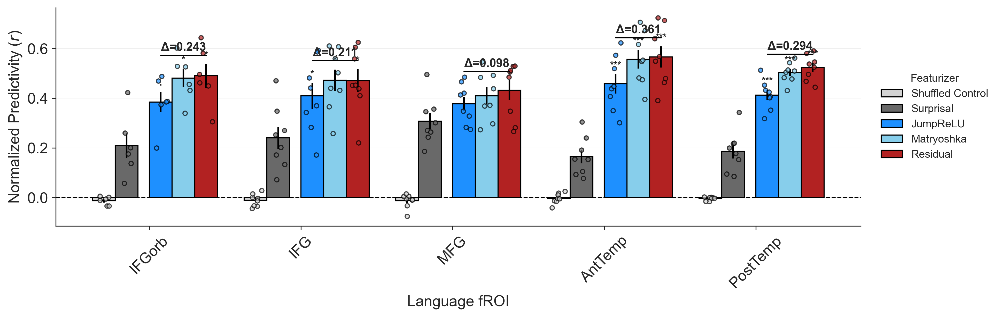

In [4]:
fig, ax = regression_utils.predictivity_bar_plot(
    add_significance=True,
    significance_annotations=annotations,
    grouping="fROI",
    ycol="NC Normalized R Fischer",
    results_suffix="_langfroi12345_20260311"
    )
fig.savefig("figures/preprint/study3_froi_barplot.pdf", bbox_inches="tight")

## Generate fROI Generalization Heatmap

In [3]:
generalization_results = os.path.join("..", "results", "fROI", "full_features", "generalization_8000", "sae", "gemma-2-2b-res-matryoshka-dc", "mean", "12", "standardized_betas", "results.csv")
df = pd.read_csv(generalization_results)

In [4]:
similarity, voxels = generalization_utils.run_cluster_generalization_analysis(df)

In [9]:
clust1 = (810, 910)
clust2 = (1361, 1543)

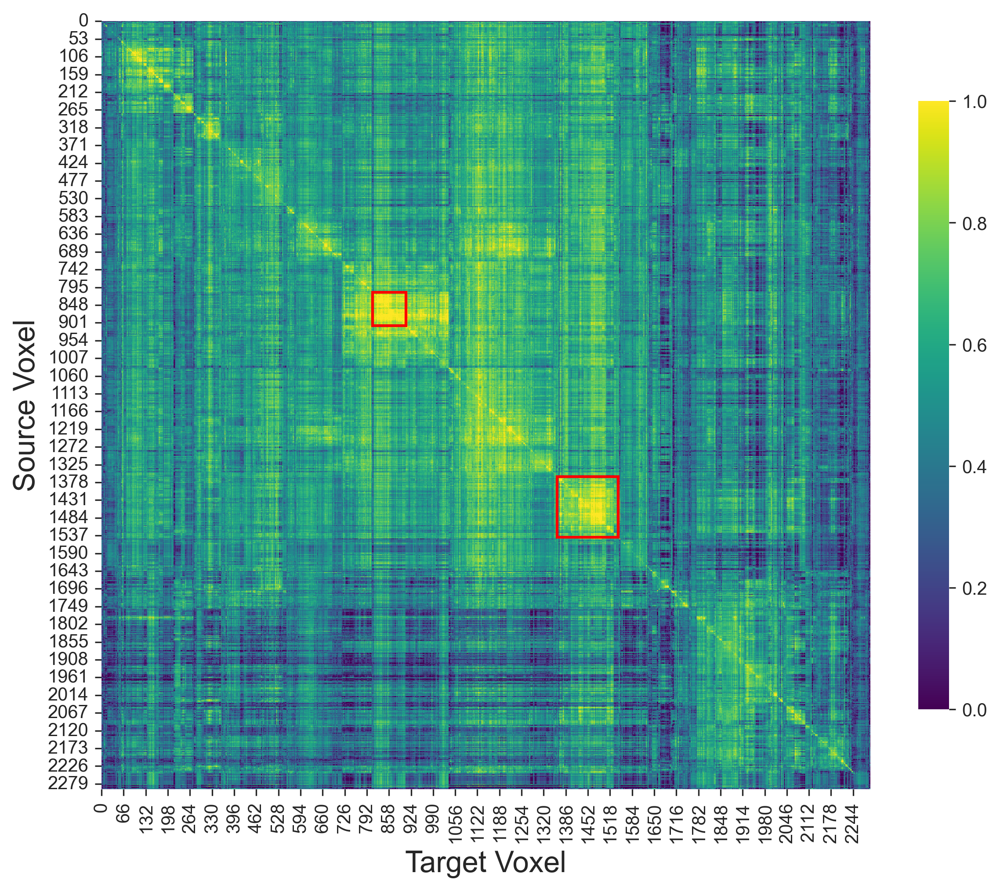

In [10]:
fig = generalization_utils.plot_similarity_matrix(similarity, rectangle_edges=[clust1, clust2], dpi=300)
fig.savefig("figures/preprint/study3_froi_generalization.pdf", bbox_inches="tight")

In [9]:
# --- Parse the two generalization clusters ---
cluster1_voxels = qualitative_utils.parse_voxel_list(voxels[clust1[0]:clust1[1]])
cluster2_voxels = qualitative_utils.parse_voxel_list(voxels[clust2[0]:clust2[1]])
print(f"Cluster 1: {len(cluster1_voxels)} voxels (indices {clust1[0]}–{clust1[1]})")
print(f"Cluster 2: {len(cluster2_voxels)} voxels (indices {clust2[0]}–{clust2[1]})")

Cluster 1: 100 voxels (indices 810–910)
Cluster 2: 182 voxels (indices 1361–1543)


### Add Nested Heatmap

In [ ]:
_, ax_nh = generalization_utils.create_nested_heatmap(df)
ax_nh.figure.savefig("figures/preprint/study3_froi_nested_heatmap.pdf", bbox_inches="tight")

### Most Widely Selected Features Across All Language fROI Voxels

All deduplicated langfroi12345 voxels: 5021


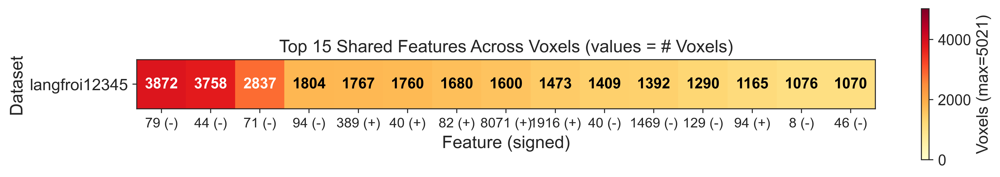

In [12]:
# --- All deduplicated langfroi12345 voxels (5021) ---
import glob as _glob

qual_path = os.path.join("..", "results", "fROI", "full_features", "regressions", "sae",
                         "gemma-2-2b-res-matryoshka-dc", "mean", "12", "standardized_betas",
                         "regressions", "qualitative")
qual_concat_path = os.path.join(qual_path, "_concat_langfroi12345.csv")

# (Re)build the concatenated per-participant qualitative CSV if it isn't on disk yet.
if not os.path.exists(qual_concat_path):
    qual_files = sorted(_glob.glob(os.path.join(qual_path, "*_langfroi12345_per_participant_*")))
    all_qual = pd.concat([pd.read_csv(f) for f in qual_files], ignore_index=True)
    all_qual.to_csv(qual_concat_path, index=False)

all_froi_stats = qualitative_utils.analyze_raw_feature_sharing(
    qual_concat_path, datasets=["langfroi12345"])

total_all = len(pd.read_csv(qual_concat_path))
print(f"All deduplicated langfroi12345 voxels: {total_all}")

fig, ax = qualitative_utils.plot_top_features_heatmap(all_froi_stats, max_voxels=total_all, top_n=15, format="landscape")
fig.savefig("figures/preprint/study3_all_froi_top15_heatmap.pdf", bbox_inches="tight")
fig.savefig("figures/preprint/study3_all_froi_top15_heatmap.svg", bbox_inches="tight")


Generalization voxels: 2296


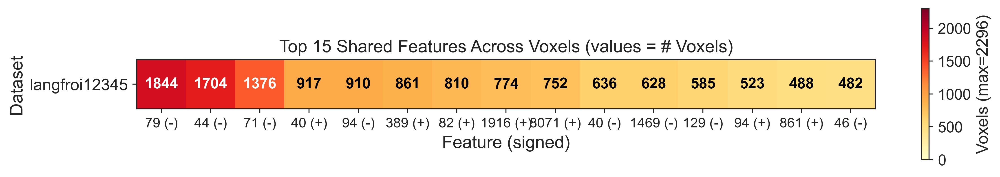

In [13]:
# --- Restricted to 2296 generalization voxels ---
gen_voxels = qualitative_utils.parse_voxel_list(voxels)  # all 2296 from generalization ordering
gen_froi_stats = qualitative_utils.analyze_raw_feature_sharing(
    qual_concat_path, datasets=["langfroi12345"], voxels=gen_voxels)

print(f"Generalization voxels: {len(gen_voxels)}")

fig, ax = qualitative_utils.plot_top_features_heatmap(gen_froi_stats, max_voxels=len(gen_voxels), top_n=15, format="landscape")
fig.savefig("figures/preprint/study3_gen_froi_top15_heatmap.pdf", bbox_inches="tight")
fig.savefig("figures/preprint/study3_gen_froi_top15_heatmap.svg", bbox_inches="tight")

# Feature Granularity Plots

## Feature Granularity: Granular Histogram

In [ ]:
qualitative_dir = os.path.join("..", "results", "fROI", "full_features", "regressions", "sae", "gemma-2-2b-res-matryoshka-dc", "mean", "12", "standardized_betas", "regressions", "qualitative")
qualitative_glob = "*_langfroi12345_2026*"
fig = regression_utils.feature_index_plot(grouping="fROI", collapsed=True, qual_dir=qualitative_dir, qual_glob=qualitative_glob)
fig.savefig("figures/preprint/feature_index_histogram_froi.pdf", bbox_inches="tight")

## Feature Granularity: Binned Barplots

In [ ]:
qualitative_dir = os.path.join("..", "results", "fROI", "full_features", "regressions", "sae", "gemma-2-2b-res-matryoshka-dc", "mean", "12", "standardized_betas", "regressions", "qualitative")
qualitative_glob = "*_langfroi12345_2026*"
fig_gran = regression_utils.granularity_bar_plot(grouping="fROI", qual_dir=qualitative_dir, qual_glob=qualitative_glob)
fig_gran.savefig("figures/preprint/study3_froi_granularity_barplot.pdf", bbox_inches="tight")

## Bin-Level Predictivity

In [ ]:
feature_sets = ["Surprisal", "_0_128", "_128_512", "_512_2048", "_2048_8192", "_8192_None"]
fig_bl, _ = regression_utils.restricted_set_analysis(grouping="fROI", feature_sets=feature_sets)
fig_bl.savefig("figures/preprint/study3_froi_bin_level.pdf", bbox_inches="tight")

# Feature Specificity Plot

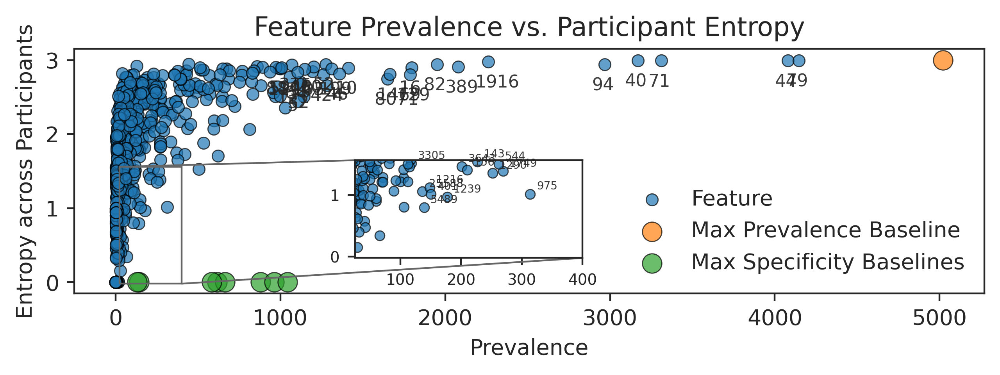

In [5]:
qualitative_dir = os.path.join("..", "results", "fROI", "full_features", "regressions", "sae", "gemma-2-2b-res-matryoshka-dc", "mean", "12", "standardized_betas", "regressions", "qualitative")
qualitative_glob = "*_langfroi12345_2026*"
fig, _ = regression_utils.feature_specificity_analysis(qual_dir=qualitative_dir, qual_glob=qualitative_glob, norm_per_participant=True)
fig.savefig("figures/preprint/feature_specificity.pdf", bbox_inches="tight")

In [ ]:
from scipy.stats import entropy
entropy([1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
# Same plot as Feature Specificity, but entropy across fROIs (5 regions, ceiling = log2(5) ≈ 2.32 bits)
# instead of across participants. Top-right = features that are both broadly used AND spread across all fROIs;
# bottom-right = high-prevalence features concentrated in one fROI.
qualitative_dir = os.path.join("..", "results", "fROI", "full_features", "regressions", "sae", "gemma-2-2b-res-matryoshka-dc", "mean", "12", "standardized_betas", "regressions", "qualitative")
qualitative_glob = "*_langfroi12345_2026*"
fig, _ = regression_utils.feature_specificity_analysis(
    qual_dir=qualitative_dir,
    qual_glob=qualitative_glob,
    norm_per_participant=True,
    grouping="fROI",
)
fig.savefig("figures/preprint/feature_specificity_froi.pdf", bbox_inches="tight")


# Appendix Plots

## Appendix: Feature Granularity: First Bin Predictivity vs. All

In [ ]:
fig_rs, _ = regression_utils.restricted_set_analysis(grouping="fROI")
fig_rs.savefig("figures/preprint/study3_appendix_froi_restricted_set.pdf", bbox_inches="tight")

## Appendix: Categories Granular Histogram

In [ ]:
fig_ch = regression_utils.feature_index_plot(grouping="Dataset", collapsed=True, categories=["abstract", "concrete"])
fig_ch.savefig("figures/preprint/study3_appendix_categories_histogram.pdf", bbox_inches="tight")

## Appendix: Categories Binned Barplots

In [ ]:
fig_cb = regression_utils.granularity_bar_plot(grouping="Dataset")
fig_cb.savefig("figures/preprint/study3_appendix_categories_granularity_barplot.pdf", bbox_inches="tight")

## Appendix: Categories First Bin Predictivity vs. All

In [ ]:
fig_cr, _ = regression_utils.restricted_set_analysis(grouping="Dataset")
fig_cr.savefig("figures/preprint/study3_appendix_categories_restricted_set.pdf", bbox_inches="tight")

## Appendix: Categories Bin-Level Predictivity

In [ ]:
feature_sets = ["Surprisal", "_0_128", "_128_512", "_512_2048", "_2048_8192", "_8192_None"]
fig_cbl, _ = regression_utils.restricted_set_analysis(grouping="Dataset", feature_sets=feature_sets, categories=["abstract", "concrete"])
fig_cbl.savefig("figures/preprint/study3_appendix_categories_bin_level.pdf", bbox_inches="tight")

## Appendix: Support Size per Featurizer

Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...


Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting results suffix: results_langfroi12345_20260311.csv ...
Attempting

/oscar/data/epavlick/mlepori/projects/Neuroscope/analysis/regression_utils.py:545: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["Participant", group_col, "Featurizer"], as_index=False)["Feature Mean"].mean()


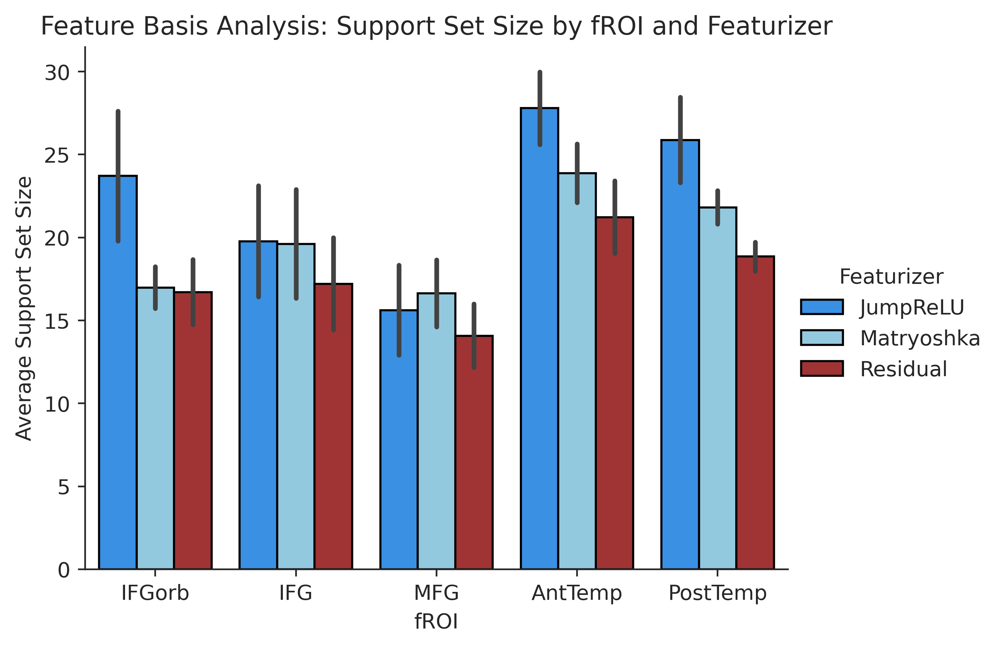

In [4]:
fig = regression_utils.feature_basis_plot(grouping="fROI")
fig.savefig("figures/preprint/study3_appendix_support_set_size.pdf", bbox_inches="tight")

## Appendix: Qualitative Interpretations of fROI Generalization Clusters

## Appendix: S3T Baseline Average — fROI Predictivity (CV Split SEM)

In [ ]:
import numpy as np

"""
The NC values used for normalization match the values reported in the public repo https://github.com/gretatuckute/drive_suppress_brains
For instance, for LH PostTemp fROI, the NC (in Pearson units) is 0.579 and the NCSNR is 0.318. The NC was supplied in Pearson, and hence should not go through another sqrt operation.
This is different from the 7T data--here, the NC in the meta files is computed via:
nc = neural_meta['ncsnr'] ** 2 / (neural_meta['ncsnr'] ** 2 + 1 / n_reps) * 100

While for 3T, it is:
noiseceiling_temp = np.square(ncsnr) / (np.square(ncsnr) + (1 / NC_n))
noiseceiling = np.sqrt(noiseceiling_temp)
(it was multiplied by 100, so below we divide again)

So, in the 3T avg meta, the value saved should not undergo the additional sqrt in the regression pipeline.
Therefore, we normalize here using raw R Fischer / (nc_meta / 100).
"""

# --- S3T baseline_avg fROI bar plot (error bars = CV split SEM) ---
S3T_BASE = os.path.join("..", "results", "fROI", "full_features", "regressions")
S3T_PARTICIPANT = "S3T_baseline_avg"
S3T_SUFFIX = "results_langfroi12345.csv"
S3T_META = os.path.join("..", "data", "processed_csvs_anon", S3T_PARTICIPANT, "langfroi12345_meta.csv")

S3T_FEATURIZER_PATHS = {
    "Shuffled Control": os.path.join(S3T_BASE, "hidden_states", "control", "mean", "12", "standardized_betas", "regressions", S3T_PARTICIPANT, S3T_SUFFIX),
    "Surprisal":        os.path.join(S3T_BASE, "logprobs_only", "", "mean", "12", "standardized_betas", "regressions", S3T_PARTICIPANT, S3T_SUFFIX),
    "JumpReLU":         os.path.join(S3T_BASE, "sae", "gemma-scope-2b-pt-res-canonical", "mean", "12", "standardized_betas", "regressions", S3T_PARTICIPANT, S3T_SUFFIX),
    "Matryoshka":       os.path.join(S3T_BASE, "sae", "gemma-2-2b-res-matryoshka-dc", "mean", "12", "standardized_betas", "regressions", S3T_PARTICIPANT, S3T_SUFFIX),
    "Residual":         os.path.join(S3T_BASE, "hidden_states", "", "mean", "12", "standardized_betas", "regressions", S3T_PARTICIPANT, S3T_SUFFIX),
}

FROI_NAME_MAP = {
    "lang_LH_IFGorb": "IFGorb",
    "lang_LH_IFG": "IFG",
    "lang_LH_MFG": "MFG",
    "lang_LH_AntTemp": "AntTemp",
    "lang_LH_PostTemp": "PostTemp",
}
FROI_ORDER_S3T = ["IFGorb", "IFG", "MFG", "AntTemp", "PostTemp"]

# Load meta to get correct NC (stored as correlation * 100, NOT variance fraction * 100)
meta_s3t = pd.read_csv(S3T_META)
nc_by_neuroid = dict(zip(meta_s3t["neuroid_id"], meta_s3t["nc"] / 100))  # correct correlation ceiling

featurizers_s3t = ["Shuffled Control", "Surprisal", "JumpReLU", "Matryoshka", "Residual"]
palette_s3t = helpers.PALETTE

# Load results and recompute normalization using correct NC
dfs_s3t = []
for feat, path in S3T_FEATURIZER_PATHS.items():
    df_tmp = pd.read_csv(path)
    df_tmp["Featurizer"] = feat
    df_tmp["fROI"] = df_tmp["Parcel Name"].map(FROI_NAME_MAP)
    # Correct normalization: R Fischer / (nc_meta / 100)
    df_tmp["NC Norm R Fischer (corrected)"] = df_tmp.apply(
        lambda r: r["R Fischer"] / nc_by_neuroid[r["neuroid"]], axis=1)
    df_tmp["NC Norm R Fischer SEM (corrected)"] = df_tmp.apply(
        lambda r: r["R Fischer SEM"] / nc_by_neuroid[r["neuroid"]], axis=1)
    dfs_s3t.append(df_tmp)
df_s3t = pd.concat(dfs_s3t, ignore_index=True)

ycol_s3t = "NC Norm R Fischer (corrected)"
sem_col_s3t = "NC Norm R Fischer SEM (corrected)"

# Grouped bar plot
n_frois = len(FROI_ORDER_S3T)
n_feats = len(featurizers_s3t)
bar_w = 0.15
gap_frac = 0.5
offsets = (np.arange(n_feats) - (n_feats - 1) / 2.0) * bar_w
gap_idx = 1  # gap after Surprisal
offsets = offsets + (np.arange(n_feats) > gap_idx) * (gap_frac * bar_w)
x = np.arange(n_frois)

fig, ax = plt.subplots(figsize=(13, 4.5), dpi=300)

for j, feat in enumerate(featurizers_s3t):
    vals = []
    errs = []
    for froi in FROI_ORDER_S3T:
        row = df_s3t[(df_s3t["Featurizer"] == feat) & (df_s3t["fROI"] == froi)]
        vals.append(row[ycol_s3t].values[0] if len(row) > 0 else 0)
        errs.append(row[sem_col_s3t].values[0] if len(row) > 0 else 0)
    ax.bar(x + offsets[j], vals, width=bar_w, yerr=errs, capsize=0,
           color=palette_s3t[feat], edgecolor="black", linewidth=1,
           label=feat, zorder=3)

ax.axhline(0, color="black", linestyle="--", linewidth=1.0, zorder=2)
ax.set_ylabel("Normalized Predictivity ($r$)", fontsize=14)
ax.set_xlabel("Language fROI", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(FROI_ORDER_S3T, rotation=45, ha="center", fontsize=14)
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.grid(True, linestyle="-", linewidth=0.5, alpha=0.3, zorder=0)
ax.xaxis.grid(False)
ax.set_title("S3T Baseline Average: fROI Predictivity (corrected NC normalization, CV split SEM)", fontsize=13)
ax.legend(title="Featurizer", frameon=False, loc="center left",
          bbox_to_anchor=(1.02, 0.5), borderaxespad=0.0)
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig("figures/preprint/study3_s3t_froi_barplot.pdf", bbox_inches="tight")
plt.show()

## Appendix: Matryoshka Bucket Statistics

Per-bucket counts of alive (non-zero) vs. dead features in the Matryoshka SAE, plus survival curves of how many alive features fire on ≥ N sentences. Bucket colors match the bin-level predictivity bar plot.


In [ ]:
# Per-bucket alive-feature stats + firing-count survival curves.
# Loads the cached Matryoshka SAE activations directly. Bucket colors line up
# with regression_utils.RESTRICTED_FEATURES_PALETTE (same colors used in the
# bin-level predictivity bar plot).
import pickle as pkl
import numpy as np

FEATURES_PATH = os.path.join("..", "features", "gemma-2-2b", "sae",
                             "gemma-2-2b-res-matryoshka-dc", "mean", "12.pkl")
MATRYOSHKA_BOUNDARIES = [0, 128, 512, 2048, 8192, 32768]
BUCKET_KEYS = ["_0_128", "_128_512", "_512_2048", "_2048_8192", "_8192_None"]
BUCKET_LABELS = [regression_utils.RESTRICTED_LABELS_MAP[k] for k in BUCKET_KEYS]
BUCKET_COLORS = [regression_utils.RESTRICTED_FEATURES_PALETTE[k] for k in BUCKET_KEYS]

activations = pkl.load(open(FEATURES_PATH, "rb"))
n_sentences = activations.shape[0]

# ---- per-bucket table ----
rows = []
firing_counts = {}  # bucket_idx -> array of fires-per-alive-feature
for i in range(len(MATRYOSHKA_BOUNDARIES) - 1):
    lo, hi = MATRYOSHKA_BOUNDARIES[i], MATRYOSHKA_BOUNDARIES[i + 1]
    chunk = activations[:, lo:hi]
    size = hi - lo
    fires_per_feat = (chunk != 0).sum(axis=0)
    nz_mask = fires_per_feat > 0
    n_nz = int(nz_mask.sum())
    pct_nz = 100.0 * n_nz / size
    fires_alive = fires_per_feat[nz_mask]
    rows.append({
        "Bucket": i + 1,
        "Range": BUCKET_LABELS[i],
        "N feats": size,
        "N non-zero": f"{n_nz:,} ({pct_nz:.1f}%)",
        "Min sentences fired": int(fires_alive.min()) if len(fires_alive) else 0,
        "Max sentences fired": int(fires_alive.max()) if len(fires_alive) else 0,
    })
    firing_counts[i] = fires_alive

bucket_table = pd.DataFrame(rows)
display(bucket_table)

# ---- two survival-count panels (NOT CDFs): full range + zoom on 50-200 sentences ----
# y = # non-zero features with fires >= N; decreasing with N, unnormalized count
thresholds = np.arange(1, n_sentences + 1)
raw = {i: np.array([(fc >= t).sum() for t in thresholds]) for i, fc in firing_counts.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=300)
panels = [
    ("All sentences", (1, n_sentences), [1, 25, 50, 75, 100, 125, 150, 175, n_sentences]),
    (f"Zoom: 50–{n_sentences} sentences", (50, n_sentences),
     [50, 75, 100, 125, 150, 175, n_sentences]),
]
for ax, (title, xlim, xticks) in zip(axes, panels):
    for i, rc in raw.items():
        ax.plot(thresholds, rc, color=BUCKET_COLORS[i], linewidth=2,
                label=f"Bucket {i + 1} ({BUCKET_LABELS[i]})")
    ax.set_xlabel("Fires on ≥ N sentences", fontsize=14)
    ax.set_ylabel("Number of non-zero features", fontsize=14)
    ax.set_title(title, fontsize=13)
    ax.set_xlim(xlim)
    ax.set_xticks(xticks)
    x_lo, x_hi = xlim
    ax.tick_params(axis="both", which="major", labelsize=13)
    y_max = max(rc[(x_lo - 1):x_hi].max() for rc in raw.values())
    ax.set_ylim(0, y_max * 1.05)
    sns.despine(ax=ax)
axes[0].legend(fontsize=11, frameon=False, loc="upper right")
fig.suptitle("Number of non-zero features firing on ≥ N sentences", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig("figures/preprint/study3_appendix_matryoshka_bucket_firing.pdf", bbox_inches="tight")
plt.show()


## Appendix: fROI-First Nested Heatmap

Same generalization matrix as the main nested heatmap, sorted by fROI first (then by participant within each fROI). Thick separator lines mark fROI boundaries; thin lines mark participants within each fROI.


In [ ]:
# Same generalization matrix as the main nested heatmap, but sorted by fROI first
# (thick lines = fROI boundaries; thin lines = participant boundaries within each fROI).
# Useful for reading the fROI-level structure of the matrix directly.
_, ax_nh_froi = generalization_utils.create_nested_heatmap(df, sort_order="fROI_first")
ax_nh_froi.figure.savefig(
    "figures/preprint/study3_appendix_froi_nested_heatmap_byROI.pdf",
    bbox_inches="tight",
)


# Talk Figures: Language fROIs (averaged)

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path
import glob as _glob

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
sns.set_style("ticks")

# ---------- Talk palette ----------
TALK_PALETTE = {
    "Shuffled Control": "lightgray",
    "Surprisal": "dimgray",
    "JumpReLU": "#7bafd4",
    "Matryoshka": "#2aadad",
    "Residual": "#f1a2a2",
}
TALK_BUCKET_COLORS = ["#0d7377", "#1a9e96", "#36bfb3", "#6dd9cd", "#a8ede5"]
MATRYOSHKA_LEVELS = [128, 512, 2048, 8192, 32768]
LOGPROB_MARKER = 32768

# ---------- Plot 1: Averaged predictivity bar plot ----------
featurizers = ["Shuffled Control", "Surprisal", "JumpReLU", "Matryoshka", "Residual"]
_feat_to_load = {"Shuffled Control": "Residual", "Surprisal": "Log Probabilities"}
ycol = "NC Normalized R Fischer"

dfs = []
for feat in featurizers:
    for pid in helpers.PARTICIPANTS:
        load_name = _feat_to_load.get(feat, feat)
        control = feat == "Shuffled Control"
        tmp = helpers.load_data(load_name, pid, dataset="fROI", layer=12,
                                control=control, meta_basename="langfroi12345",
                                results_suffix="_langfroi12345_20260311")
        tmp["Featurizer"] = feat
        tmp["Participant"] = pid
        dfs.append(tmp)
df_all = pd.concat(dfs, ignore_index=True)
df_all["fROI"] = df_all["top10_tstat_langloc_SN_parc_lang_int"].map(helpers.FROI_MAP)

# Average across fROIs per participant, then mean ± SEM across participants
df_avg = df_all.groupby(["Participant", "Featurizer"], as_index=False, observed=True)[ycol].mean()
mean_vals = df_avg.groupby("Featurizer", observed=True)[ycol].mean().reindex(featurizers)
sem_vals = df_avg.groupby("Featurizer", observed=True)[ycol].sem().reindex(featurizers)

fig, ax = plt.subplots(figsize=(4.5, 5), dpi=300)
bar_w = 0.55
# Position bars with a gap between Surprisal and JumpReLU to group the 3 featurizers
gap = 0.4
positions = np.array([0, 1, 2 + gap, 3 + gap, 4 + gap])
colors = [TALK_PALETTE[f] for f in featurizers]

ax.bar(positions, mean_vals.values, yerr=sem_vals.values, capsize=0,
       color=colors, edgecolor="black", linewidth=1, width=bar_w, zorder=3)

# Individual participant dots
for j, feat in enumerate(featurizers):
    sub = df_avg[df_avg["Featurizer"] == feat]
    jitter = np.random.uniform(-0.12, 0.12, len(sub))
    ax.scatter(np.full(len(sub), positions[j]) + jitter, sub[ycol].values,
               s=20, alpha=0.7, color=colors[j], edgecolor="black", linewidth=0.8, zorder=4)

ax.axhline(0, color="black", linestyle="--", linewidth=1.0, zorder=2)
ax.set_ylabel("Normalized Predictivity ($r$)", fontsize=14)
ax.set_xlabel("")
ax.set_xticks(positions)
ax.set_xticklabels(featurizers, rotation=45, ha="right", fontsize=12)
ax.tick_params(axis="y", labelsize=14)
ax.yaxis.grid(True, linestyle="-", linewidth=0.5, alpha=0.3, zorder=0)
ax.xaxis.grid(False)
ax.set_title("Average Predictivity Across Language fROIs", fontsize=14)
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig("figures/talks/talk_avg_predictivity_froi.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# ---------- Plot 2: Averaged granularity bar plot ----------
qual_dir = os.path.join("..", "results", "fROI", "full_features", "regressions", "sae",
                        "gemma-2-2b-res-matryoshka-dc", "mean", "12", "standardized_betas",
                        "regressions", "qualitative")
qual_glob = "*_langfroi12345_2026*"

files = sorted(_glob.glob(str(Path(qual_dir) / qual_glob)))
qual_dfs = []
for f in files:
    qual_dfs.append(pd.read_csv(f))
df_qual = pd.concat(qual_dfs, ignore_index=True)

df_qual["feature_abs"] = (
    df_qual["feature_indices"]
    .apply(lambda s: [abs(int(x)) for x in re.findall(r"-?\d+", str(s))])
    .apply(lambda lst: [x for x in lst if x != LOGPROB_MARKER])
)

# Bin features into Matryoshka buckets per voxel
bucket_labels = [f"0–{MATRYOSHKA_LEVELS[0]}"]
for i in range(1, len(MATRYOSHKA_LEVELS)):
    bucket_labels.append(f"{MATRYOSHKA_LEVELS[i-1]}–{MATRYOSHKA_LEVELS[i]}")

rows = []
for _, row in df_qual.iterrows():
    counts = np.histogram(row["feature_abs"], bins=[0] + MATRYOSHKA_LEVELS)[0]
    for bi, count in enumerate(counts):
        rows.append({
            "participant": row["participant"],
            "bucket": bucket_labels[bi],
            "count": int(count),
        })
df_buckets = pd.DataFrame(rows)

# Average across all voxels per participant per bucket, then mean ± SEM across participants
df_part = df_buckets.groupby(["participant", "bucket"], as_index=False)["count"].mean()
mean_b = df_part.groupby("bucket")["count"].mean().reindex(bucket_labels)
sem_b = df_part.groupby("bucket")["count"].sem().reindex(bucket_labels)

fig, ax = plt.subplots(figsize=(4.5, 5), dpi=300)
x = np.arange(len(bucket_labels))

ax.bar(x, mean_b.values, yerr=sem_b.values, capsize=0,
       color=TALK_BUCKET_COLORS, edgecolor="black", linewidth=1, width=0.55, zorder=3)

# Individual participant dots
for bi, bucket in enumerate(bucket_labels):
    sub = df_part[df_part["bucket"] == bucket]
    jitter = np.random.uniform(-0.12, 0.12, len(sub))
    ax.scatter(np.full(len(sub), x[bi]) + jitter, sub["count"].values,
               s=20, alpha=0.7, color=TALK_BUCKET_COLORS[bi], edgecolor="black", linewidth=0.8, zorder=4)

ax.set_ylabel("Average Number of Features", fontsize=14)
ax.set_xlabel("Matryoshka Bucket", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(bucket_labels, rotation=45, ha="right", fontsize=12)
ax.tick_params(axis="y", labelsize=14)
ax.yaxis.grid(True, linestyle="-", linewidth=0.5, alpha=0.3, zorder=0)
ax.xaxis.grid(False)
ax.set_title("Feature Granularity Across Language fROIs", fontsize=14)
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig("figures/talks/talk_avg_granularity_froi.pdf", bbox_inches="tight")
plt.show()